# Diarization (NeMo)
nvidia/Nemotron-3-Diarization, up to 8 speakers. Results in `outputs/diarization/<name>/nemotron/`.
Restart the kernel after upgrading NeMo.

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
from nemo.collections.asr.models import SortformerEncLabelModel

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
wavs = sorted((root / "data" / "raw_audios").glob("*.wav"))
for i, p in enumerate(wavs):
    print(i, p.name)

/Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0 OyQOvi9Qhxs.wav
1 abuser.wav


In [2]:
audio_path = wavs[0]
TEST_MINUTES = None  # e.g. 5 to only use the start

out_dir = root / "outputs" / "diarization" / audio_path.stem / "nemotron"
out_dir.mkdir(parents=True, exist_ok=True)

# model wants 16 kHz mono
model_audio = out_dir / "audio_16k_mono.wav"
cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(audio_path)]
if TEST_MINUTES:
    cmd += ["-t", str(TEST_MINUTES * 60)]
cmd += ["-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", str(model_audio)]
subprocess.run(cmd, check=True)

CompletedProcess(args=['ffmpeg', '-y', '-loglevel', 'error', '-i', '/Users/macbook/Documents/IT/projects/tts/data/raw_audios/OyQOvi9Qhxs.wav', '-ar', '16000', '-ac', '1', '-c:a', 'pcm_s16le', '/Users/macbook/Documents/IT/projects/tts/outputs/diarization/OyQOvi9Qhxs/nemotron/audio_16k_mono.wav'], returncode=0)

In [3]:
model = SortformerEncLabelModel.from_pretrained("nvidia/Nemotron-3-Diarization")
model.eval()

# streaming settings, in 80 ms frames (340 = ~27 s chunks)
m = model.sortformer_modules
m.chunk_len = 340
m.chunk_right_context = 40
m.fifo_len = 40
m.spkcache_update_period = 300
m.spkcache_len = 264
model._check_streaming_parameters()

[NeMo W 2026-11-18 17:42:04 modelPT:192] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath: null
    validate_manifest_paths: false
    sample_rate: 16000
    num_spks: 8
    session_len_sec: 105
    soft_targets: false
    batch_size: 42
    shuffle: true
    num_workers: 18
    pin_memory: true
    use_lhotse: false
    subsegment_mode: true
    subsegment_single_chunk_min_len_sec: 45
    subsegment_two_chunks_rate: 0.5
    subsegment_two_chunk_min_len_sec: 22
    subsegment_nspk_bias: 1.5
    subsegment_start_guard_sec: 0.25
    subsegment_min_first_spk_sec: 0.5
    subsegment_splice_silence_sec: 0.1
    
[NeMo W 2026-11-18 17:42:04 modelPT:199] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the

[NeMo I 2026-11-18 17:42:04 save_restore_connector:309] Model SortformerEncLabelModel was successfully restored from /Users/macbook/.cache/huggingface/hub/models--nvidia--Nemotron-3-Diarization/snapshots/52a432672732425e4c19765b9fec9b5810e6f4ba/Nemotron-3-Diarization.nemo.


[NeMo W 2026-11-18 17:42:04 sortformer_modules:241] spkcache_update_period (300) is less than chunk_len (340). The effective update period will be 340.


In [4]:
segments = model.diarize(audio=[str(model_audio)], batch_size=1)

turns = sorted((float(s), float(e), spk) for s, e, spk in (line.split() for line in segments[0]))
for s, e, spk in turns[:20]:
    print(f"{spk}  {s:7.2f} - {e:7.2f}")
print(len(turns), "turns")

[NeMo I 2026-11-18 17:42:04 vad_utils:90] No postprocessing YAML file has been provided. Default postprocessing configurations will be applied.


[NeMo W 2026-11-18 17:42:04 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: subsegment_single_chunk_min_len_sec,subsegment_two_chunk_min_len_sec,num_spks,soft_label_thres,subsampling_factor,subsegment_splice_silence_sec,subsegment_min_first_spk_sec,subsegment_start_guard_sec,subsegment_two_chunks_rate,session_len_sec,subsegment_mode,validate_manifest_paths,subsegment_nspk_bias
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-18 17:42:04 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
[NeMo W 2026-11-18 17:42:04 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/nn/attention/flex_attention.py:2621: UserWarning: flex_attention called without torch.compile() - this will use an un

speaker_0     0.06 -    3.00
speaker_0     3.05 -    3.77
speaker_1     4.09 -    5.08
speaker_0     5.17 -    8.98
speaker_0     9.23 -   11.36
speaker_0    11.61 -   16.53
speaker_1    16.99 -   17.04
speaker_0    17.20 -   26.76
speaker_0    27.65 -   34.08
speaker_2    30.70 -   31.78
speaker_2    33.60 -   35.26
speaker_0    34.64 -   43.44
speaker_2    43.80 -   44.41
speaker_0    44.94 -   48.08
speaker_0    48.09 -   48.16
speaker_0    48.19 -   49.40
speaker_2    49.06 -   51.16
speaker_0    50.93 -   58.09
speaker_2    53.78 -   54.40
speaker_2    57.81 -   58.81
21 turns


saved outputs/diarization/OyQOvi9Qhxs/nemotron/OyQOvi9Qhxs.rttm
speaker_0 58.2 s
speaker_1 1.0 s
speaker_2 7.1 s


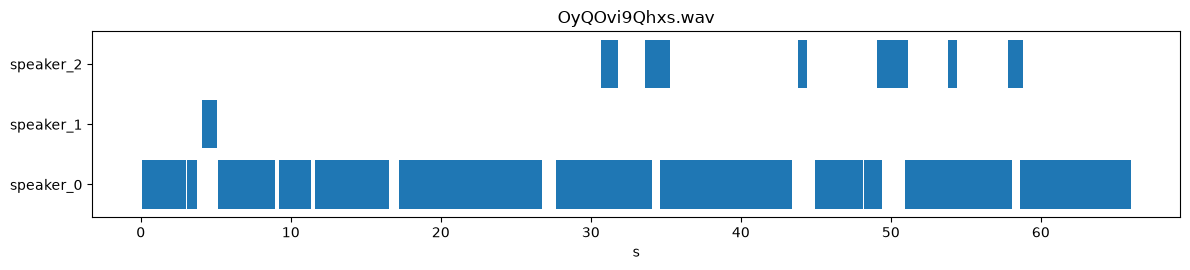

In [5]:
rttm = out_dir / f"{audio_path.stem}.rttm"
with open(rttm, "w") as f:
    for s, e, spk in turns:
        f.write(f"SPEAKER {audio_path.stem} 1 {s:.3f} {e - s:.3f} <NA> <NA> {spk} <NA> <NA>\n")
print("saved", rttm.relative_to(root))

speakers = sorted({spk for *_, spk in turns})
for spk in speakers:
    print(spk, round(sum(e - s for s, e, x in turns if x == spk), 1), "s")

fig, ax = plt.subplots(figsize=(12, 0.6 * len(speakers) + 1))
for row, spk in enumerate(speakers):
    ax.broken_barh([(s, e - s) for s, e, x in turns if x == spk], (row - 0.4, 0.8))
ax.set_yticks(range(len(speakers)), speakers)
ax.set_xlabel("s")
ax.set_title(audio_path.name)
plt.tight_layout()
plt.show()